# IBM Article Recommendation Systems

This notebook explores article recommendations using interaction data from the IBM Watson Studio community. It includes exploratory analysis, popularity-based recommendations, collaborative filtering, content-based recommendations, and matrix factorization.

## Contents

1. [Exploratory data analysis](#Exploratory-Data-Analysis)
2. [Rank-based recommendations](#Rank)
3. [User-user collaborative filtering](#User-User)
4. [Content-based recommendations](#Content-Recs)
5. [Matrix factorization](#Matrix-Fact)
6. [Evaluation and tradeoffs](#conclusions)


In [342]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import project_tests as t


df = pd.read_csv(
    'data/user-item-interactions.csv', 
    dtype={'article_id': int, 'title': str, 'email': str}
)
# Preview the interaction data.
df.head()

,Unnamed: 0,article_id,title,email
0,0,1430,"using pixiedust for fast, flexible, and easier...",ef5f11f77ba020cd36e1105a00ab868bbdbf7fe7
1,1,1314,healthcare python streaming application demo,083cbdfa93c8444beaa4c5f5e0f5f9198e4f9e0b
2,2,1429,use deep learning for image classification,b96a4f2e92d8572034b1e9b28f9ac673765cd074
3,3,1338,ml optimization using cognitive assistant,06485706b34a5c9bf2a0ecdac41daf7e7654ceb7
4,4,1276,deploy your python model as a restful api,f01220c46fc92c6e6b161b1849de11faacd7ccb2


<a id="Exploratory-Data-Analysis"></a>
## Exploratory Data Analysis

### Missing user emails

Interactions with missing emails are grouped under `unknown_user` before mapping emails to numeric user IDs.


In [343]:
# Some interactions do not have a user associated with it, assume the same user.
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 45993 entries, 0 to 45992
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   Unnamed: 0  45993 non-null  int64
 1   article_id  45993 non-null  int64
 2   title       45993 non-null  str  
 3   email       45976 non-null  str  
dtypes: int64(2), str(2)
memory usage: 1.4 MB


In [344]:
print(f"Number of Null email values is: {df['email'].isna().sum()}")

Number of Null email values is: 17


In [345]:
df[df.email.isna()]

,Unnamed: 0,article_id,title,email
25131,25146,1016,why you should master r (even if it might even...,NaN
29758,30157,1393,the nurse assignment problem,NaN
29759,30158,20,working interactively with rstudio and noteboo...,NaN
29760,30159,1174,breast cancer wisconsin (diagnostic) data set,NaN
29761,30160,62,data visualization: the importance of excludin...,NaN
35264,36016,224,"using apply, sapply, lapply in r",NaN
35276,36029,961,beyond parallelize and collect,NaN
35277,36030,268,sector correlations shiny app,NaN
35278,36031,268,sector correlations shiny app,NaN
35279,36032,268,sector correlations shiny app,NaN


In [346]:
# Fill email NaNs with "unknown_user"
df["email"] = df["email"].fillna("unknown_user")

In [347]:
# Check if no more NaNs 
df[df.email.isna()]

,Unnamed: 0,article_id,title,email


### User activity distribution


In [348]:
# Interaction counts per user.
interactions_per_user = df.groupby('email').size()

interactions_per_user.describe()

# There are 714 unique articles in the dataset.
# There are 5149 unique users in the dataset.
# Minimum: A user has at least interacted with 1 article.
# Maximum: The maximum number of articles a user has interacted with is 364.
# Mean: The average number of articles a user has interacted with is 8.
# Median: At least 50% of the users have interacted with 3 or fewer articles.

count    5149.000000
mean        8.932414
std        16.801011
min         1.000000
25%         1.000000
50%         3.000000
75%         9.000000
max       364.000000
dtype: float64

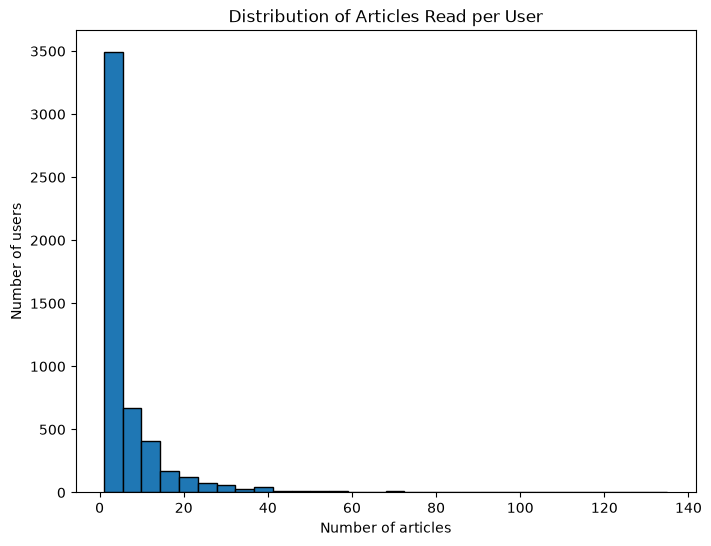

In [349]:
# Distribution of distinct articles read per user.
articles_per_user = df.groupby('email')['article_id'].nunique()
articles_per_user.describe()

fig, ax = plt.subplots(figsize=(8, 6))
ax.hist(articles_per_user, bins=30, edgecolor='black')

ax.set_xlabel('Number of articles')
ax.set_ylabel('Number of users')
ax.set_title('Distribution of Articles Read per User')
plt.show()

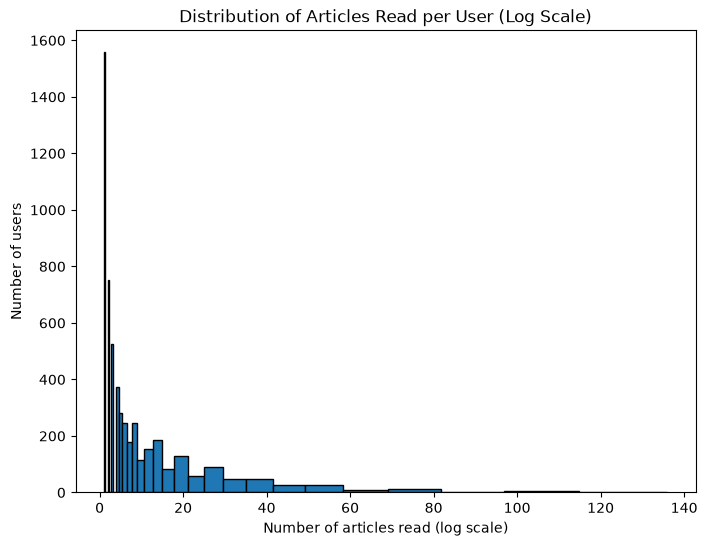

In [350]:
fig, ax = plt.subplots(figsize=(8, 6))

bins = np.geomspace(1, articles_per_user.max() + 1, num=30)
ax.hist(articles_per_user, bins=bins, edgecolor='black')

ax.set_xlabel('Number of articles read (log scale)')
ax.set_ylabel('Number of users')
ax.set_title('Distribution of Articles Read per User (Log Scale)')
plt.show()

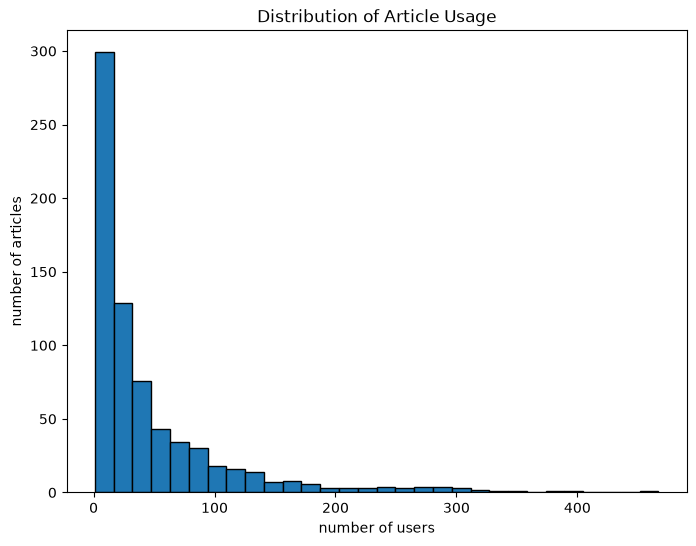

In [351]:
# Distribution of unique-reader counts per article.
article_read_count = df.groupby('article_id')['email'].nunique()

fig, ax = plt.subplots(figsize=(8, 6))
ax.hist(article_read_count, bins=30, edgecolor='black')

plt.xlabel('number of users')
plt.ylabel('number of articles')
plt.title('Distribution of Article Usage')
plt.show()

In [352]:
# Median and maximum interaction counts per user.

median_val =  3 # 50% of individuals interact with 3 number of articles or fewer.
max_views_by_user = 364 # The maximum number of user-article interactions by any 1 user is 364.

### Dataset size and unique users and articles


In [353]:
unique_articles =  df[df['email'] != 'unknown_user']['article_id'].nunique() # The number of unique articles that have at least one interaction
total_articles =  df['article_id'].nunique() # The number of unique articles on the IBM platform
unique_users =  df['email'].nunique() # The number of unique users
user_article_interactions = len(df) # The number of user-article interactions

print(f"Number of unique articles that have at least one interaction: {unique_articles}")
print(f"Total number of unique articles on the IBM platform: {total_articles}")
print(f"Number of unique users: {unique_users}")
print(f"Number of user-article interactions: {user_article_interactions}")

Number of unique articles that have at least one interaction: 714
Total number of unique articles on the IBM platform: 714
Number of unique users: 5149
Number of user-article interactions: 45993


### Article popularity and user identifiers


In [354]:
most_viewed_article_id = df['article_id'].value_counts().index[0]  # The article_id of the most viewed article in the dataset, as an integer 
max_views = df['article_id'].value_counts().iloc[0] # The most viewed article in the dataset was viewed how many times? 937 times

print(f"The most viewed article ID is: {most_viewed_article_id}")
print(f"The most viewed article was viewed {max_views} times.")

The most viewed article ID is: 1429
The most viewed article was viewed 937 times.


In [355]:
# Map emails to numeric user IDs.

def email_mapper(df=df):
    coded_dict = {
        email: num 
        for num, email in enumerate(df['email'].unique(), start=1)
    }
    return [coded_dict[val] for val in df['email']]

df['user_id'] = email_mapper(df)
del df['email']

# show header
df.head()

,Unnamed: 0,article_id,title,user_id
0,0,1430,"using pixiedust for fast, flexible, and easier...",1
1,1,1314,healthcare python streaming application demo,2
2,2,1429,use deep learning for image classification,3
3,3,1338,ml optimization using cognitive assistant,4
4,4,1276,deploy your python model as a restful api,5


In [356]:

sol_1_dict = {
    '`50% of individuals have _____ or fewer interactions.`': median_val,
    '`The total number of user-article interactions in the dataset is ______.`': user_article_interactions,
    '`The maximum number of user-article interactions by any 1 user is ______.`': max_views_by_user,
    '`The most viewed article in the dataset was viewed _____ times.`': max_views,
    '`The article_id of the most viewed article is ______.`': most_viewed_article_id,
    '`The number of unique articles that have at least 1 rating ______.`': unique_articles,
    '`The number of unique users in the dataset is ______`': unique_users,
    '`The number of unique articles on the IBM platform`': total_articles
}

# Validate dataset statistics.
t.sol_1_test(sol_1_dict)

It looks like you have everything right here! Nice job!


<a id="Rank"></a>
## Rank-Based Recommendations

The dataset contains interactions rather than explicit ratings. Articles are ranked by their interaction frequency.


In [357]:
def get_top_articles(n, df=df):
    """
    INPUT:
    n - (int) the number of top articles to return
    df - (pandas dataframe) df as defined at the top of the notebook 
    
    OUTPUT:
    top_articles - (list) A list of the top 'n' article titles 
    
    """
    
    top_articles = df.groupby('title').size().sort_values(ascending=False).head(n).index.tolist()
    
    return top_articles # Return the top article titles from df

def get_top_article_ids(n, df=df):
    """
    INPUT:
    n - (int) the number of top articles to return
    df - (pandas dataframe) df as defined at the top of the notebook 
    
    OUTPUT:
    top_articles - (list) A list of the top 'n' article titles 
    
    """
    top_articles = df.groupby('article_id').size().sort_values(ascending=False).head(n).index.tolist()
 
    return top_articles # Return the top article ids

In [358]:
print(get_top_articles(10))
print(get_top_article_ids(10))

['use deep learning for image classification', 'insights from new york car accident reports', 'visualize car data with brunel', 'use xgboost, scikit-learn & ibm watson machine learning apis', 'predicting churn with the spss random tree algorithm', 'healthcare python streaming application demo', 'finding optimal locations of new store using decision optimization', 'apache spark lab, part 1: basic concepts', 'analyze energy consumption in buildings', 'gosales transactions for logistic regression model']
[1429, 1330, 1431, 1427, 1364, 1314, 1293, 1170, 1162, 1304]


In [359]:
# Popularity recommendations at three list sizes.
top_5 = get_top_articles(5)
top_10 = get_top_articles(10)
top_20 = get_top_articles(20)

# Validate popularity recommendations.
t.sol_2_test(get_top_articles)

Your top_5 looks like the solution list! Nice job.
Your top_10 looks like the solution list! Nice job.
Your top_20 looks like the solution list! Nice job.


<a id="User-User"></a>
## User-User Collaborative Filtering

### Binary user–article matrix

Rows represent users and columns represent articles. A value of 1 indicates at least one interaction; 0 indicates no recorded interaction. Repeated reads are represented by a single 1.


In [360]:
df.query('article_id == 1429').nunique()

Unnamed: 0    937
article_id      1
title           1
user_id       397
dtype: int64

In [361]:
# create the user-article matrix with 1's and 0's

def create_user_item_matrix(df, fill_value=0):
    """
    INPUT:
    df - pandas dataframe with article_id, title, user_id columns
    
    OUTPUT:
    user_item - user item matrix 
    
    Description:
    Return a matrix with user ids as rows and article ids on the columns with 1 values where a user interacted with 
    an article and a 0 otherwise
    """
    user_item = pd.crosstab(df['user_id'], df['article_id'])
    user_item = (user_item > 0).astype(int)

    if fill_value != 0:
        user_item = user_item.mask(user_item == 0, fill_value)
    
    return user_item # return the user_item matrix 

user_item = create_user_item_matrix(df)

In [362]:
# Validate the binary interaction matrix.
assert user_item.shape[0] == 5149, "Oops!  The number of users in the user-article matrix doesn't look right."
assert user_item.shape[1] == 714, "Oops!  The number of articles in the user-article matrix doesn't look right."
assert user_item.sum(axis=1)[1] == 36, "Oops!  The number of articles seen by user 1 doesn't look right."
print("You have passed our quick tests!  Please proceed!")

You have passed our quick tests!  Please proceed!


### User similarity

The basic similarity function ranks other users by the dot product of their binary interaction vectors and excludes the target user.


In [363]:
from sklearn.metrics.pairwise import cosine_similarity

In [364]:
def find_similar_users(user_id, user_item=user_item, include_similarity=False):
    """
    INPUT:
    user_id - (int) a user_id
    user_item - (pandas dataframe) matrix of users by articles: 
                1's when a user has interacted with an article, 0 otherwise
    include_similarity - (bool) whether to include the similarity in the output
    
    OUTPUT:
    similar_users - (list) an ordered list where the closest users (largest dot product users)
                    are listed first
    
    Description:
    Computes the similarity of every pair of users based on the dot product
    Returns an ordered list of user ids. If include_similarity is True, returns a list of lists
    where the first element is the user id and the second the similarity.
    
    """

    provided_user = user_item.loc[[user_id]]
    
    # compute similarity of each user to the provided user
    similarity = provided_user.dot(user_item.transpose())

    # sort by similarity
    similarity_sorted = similarity.T.sort_values(by=user_id, ascending=False)
    # remove the own user's id
    similarity_sorted = similarity_sorted.drop(index=user_id)
    
    # create list of just the ids
    most_similar_users = similarity_sorted.index.tolist()
    
    # create list of just the similarities
    similarity_scores = similarity_sorted[user_id].tolist()
    similar_users_with_scores = [
        list(pair) for pair in similarity_sorted[user_id].items()
    ]
    if include_similarity:
        return similar_users_with_scores # return a list of lists with [[similar_user_id, similarity], ...]
    return most_similar_users # return a list of the users in order from most to least similar
        

In [365]:
# Example similar-user rankings.
print("The 10 most similar users to user 1 are: {}".format(find_similar_users(1)[:10]))
print("The 5 most similar users to user 3933 are: {}".format(find_similar_users(3933)[:5]))
print("The 3 most similar users to user 46 are: {}".format(find_similar_users(46)[:3]))

The 10 most similar users to user 1 are: [3933, 23, 3782, 203, 4459, 3870, 131, 4201, 46, 5041]
The 5 most similar users to user 3933 are: [1, 23, 3782, 203, 4459]
The 3 most similar users to user 46 are: [4201, 3782, 23]


### Recommendations from similar users


In [366]:
article_ids = [1434, 1435, 1436, 1437]
df_articles = df[df["article_id"].isin(article_ids)]
article_value_counts = df_articles.groupby("article_id")["user_id"].size().sort_values(ascending=False)


article_counts = user_item[article_ids].sum(axis=0)
ranked_article_unique_counts = list(article_counts.sort_values(ascending=False).items())
ranked_article_unique_counts = [
    list(pair) for pair in ranked_article_unique_counts
]
print(ranked_article_unique_counts)

[[1436, 282], [1437, 127], [1435, 75], [1434, 36]]


In [367]:
def get_article_names(article_ids, df=df):
    """
    INPUT:
    article_ids - (list) a list of article ids
    df - (pandas dataframe) df as defined at the top of the notebook
    
    OUTPUT:
    article_names - (list) a list of article names associated with the list of article ids 
                    (this is identified by the title column in df)
    """

    titles = df.drop_duplicates('article_id').set_index('article_id')['title']
    article_names = titles.loc[list(article_ids)].tolist()
    return article_names # Return the article names associated with list of article ids

def get_ranked_article_unique_counts(article_ids, user_item=user_item):
    """
    INPUT:
    article_ids - (list) a list of article ids to evaluate (a subset to rank).
                the dtype should match the column labels in `user_item`.
    user_item - (pandas dataframe) a binary matrix of users by articles [n_users x n_articles]:
                1's when a user has interacted with an article, 0 otherwise 
                columns are article IDs.
    
    OUTPUT:
    ranked_article_unique_counts - (list) a list of tuples [(article_id, unique_user_count)]
                     only for the provided `article_ids` with article_id and number of unique
                     users that have interacted with the article, sorted by the number of unique
                     users in descending order
    
    Description:
    For each `article_id` in the input list, count the number of unique users who
    interacted with it (column sum in the binary `user_item` matrix).
    Return the (article_id, count) pairs sorted in descending order.
    """
    
    article_counts = user_item[article_ids].sum(axis=0)
    ranked_article_unique_counts = list(article_counts.sort_values(ascending=False).items())
    ranked_article_unique_counts = [
        list(pair) for pair in ranked_article_unique_counts
    ]
        
    return ranked_article_unique_counts


def get_user_articles(user_id, user_item=user_item):
    """
    INPUT:
    user_id - (int) a user id
    user_item - (pandas dataframe) matrix of users by articles: 
                1's when a user has interacted with an article, 0 otherwise
    
    OUTPUT:
    article_ids - (list) a list of the article ids seen by the user
    article_names - (list) a list of article names associated with the list of article ids 
                    (this is identified by the title column in df)
    
    Description:
    Provides a list of the article_ids and article titles that have been seen by a user
    """
    user_articles = user_item.loc[user_id]
    article_ids = user_articles.index[user_articles > 0].tolist()
    article_names = get_article_names(article_ids)

    return article_ids, article_names # return the ids and names


def user_user_recs(user_id, m=10):
    """
    INPUT:
    user_id - (int) a user id
    m - (int) the number of recommendations you want for the user
    
    OUTPUT:
    recs - (list) a list of recommendations for the user
    
    Description:
    Loops through the users based on closeness to the input user_id
    For each user - finds articles the user hasn't seen before and provides them as recs
    Does this until m recommendations are found
    
    Notes:
    Users who are the same closeness are chosen arbitrarily as the 'next' user
    
    For the user where the number of recommended articles starts below m 
    and ends exceeding m, the last items are chosen arbitrarily
    
    """
    if m <= 0:
        return []
    if user_id not in user_item.index:
        return get_top_article_ids(m)

    seen = set(get_user_articles(user_id)[0])
    recs = []
    for neighbor_id in find_similar_users(user_id):
        for article_id in get_user_articles(neighbor_id)[0]:
            if article_id not in seen:
                recs.append(article_id)
                seen.add(article_id)
                if len(recs) == m:
                    return recs

    return recs # return your recommendations for this user_id    

In [368]:
# Check Results
get_article_names(user_user_recs(1, 10)) # Return 10 recommendations for user 1

['this week in data science (april 18, 2017)',
 'timeseries data analysis of iot events by using jupyter notebook',
 'got zip code data? prep it for analytics. – ibm watson data lab – medium',
 'higher-order logistic regression for large datasets',
 'using machine learning to predict parking difficulty',
 'deep forest: towards an alternative to deep neural networks',
 'experience iot with coursera',
 'using brunel in ipython/jupyter notebooks',
 'graph-based machine learning',
 'the 3 kinds of context: machine learning and the art of the frame']

In [369]:
get_ranked_article_unique_counts([1320, 232, 844])

[[1320, 123], [844, 78], [232, 62]]

In [370]:
# Validate article lookups and interaction counts.
assert set(get_article_names([1024, 1176, 1305, 1314, 1422, 1427])) == set(['using deep learning to reconstruct high-resolution audio', 'build a python app on the streaming analytics service', 'gosales transactions for naive bayes model', 'healthcare python streaming application demo', 'use r dataframes & ibm watson natural language understanding', 'use xgboost, scikit-learn & ibm watson machine learning apis']), "Oops! Your the get_article_names function doesn't work quite how we expect."
assert set(get_article_names([1320, 232, 844])) == set(['housing (2015): united states demographic measures','self-service data preparation with ibm data refinery','use the cloudant-spark connector in python notebook']), "Oops! Your the get_article_names function doesn't work quite how we expect."
assert get_ranked_article_unique_counts([1320, 232, 844])[0] == [1320, 123], "Oops! Your the get_ranked_article_unique_counts function doesn't work quite how we expect.\nMake sure you are using the user_item matrix to create the article counts."
assert set(get_user_articles(20)[0]) == set([1320, 232, 844])
assert set(get_user_articles(20)[1]) == set(['housing (2015): united states demographic measures', 'self-service data preparation with ibm data refinery','use the cloudant-spark connector in python notebook'])
assert set(get_user_articles(2)[0]) == set([1024, 1176, 1305, 1314, 1422, 1427])
assert set(get_user_articles(2)[1]) == set(['using deep learning to reconstruct high-resolution audio', 'build a python app on the streaming analytics service', 'gosales transactions for naive bayes model', 'healthcare python streaming application demo', 'use r dataframes & ibm watson natural language understanding', 'use xgboost, scikit-learn & ibm watson machine learning apis'])
print("If this is all you see, you passed all of our tests!  Nice job!")

If this is all you see, you passed all of our tests!  Nice job!


### Ranked neighbors and recommendations

The ranked variant uses cosine similarity and breaks ties by the number of distinct articles read. Neighbor IDs provide a deterministic final tie-breaker. Candidate articles are ranked by total interaction frequency, and previously read articles are excluded.


In [371]:
def get_top_sorted_users(user_id, user_item=user_item):
    """
    INPUT:
    user_id - (int)
    user_item - (pandas dataframe) matrix of users by articles: 
            1's when a user has interacted with an article, 0 otherwise
    
            
    OUTPUT:
    neighbors_df - (pandas dataframe) a dataframe with:
                    neighbor_id - is a neighbor user_id
                    similarity - cosine similarity to the provided user_id
                    num_interactions - the number of distinct articles viewed by the user
                    
    Other Details - sort the neighbors_df by the similarity and then by number of interactions where 
                    highest of each is higher in the dataframe, i.e. Descending order
     
    """
    # The ranked variant uses cosine similarity to normalize user activity.
    similarities = cosine_similarity(user_item.loc[[user_id]], user_item)[0]
    neighbors_df = pd.DataFrame({
        'neighbor_id': user_item.index,
        'similarity': similarities,
        # In the binary matrix, the row sum counts distinct articles read.
        'num_interactions': user_item.sum(axis=1).to_numpy(),
    })
    neighbors_df = neighbors_df.loc[neighbors_df['neighbor_id'] != user_id]
    neighbors_df = neighbors_df.sort_values(
        ['similarity', 'num_interactions', 'neighbor_id'],
        ascending=[False, False, True],
    ).reset_index(drop=True)
    
    return neighbors_df # Return the dataframe specified in the doc_string


def user_user_recs_part2(user_id, m=10):
    """
    INPUT:
    user_id - (int) a user id
    m - (int) the number of recommendations you want for the user
    
    OUTPUT:
    recs - (list) a list of recommendations for the user by article id
    rec_names - (list) a list of recommendations for the user by article title
    
    Description:
    Loops through the users based on closeness to the input user_id
    For each user - finds articles the user hasn't seen before and provides them as recs
    Does this until m recommendations are found
    
    Notes:
    * Choose the users that have the most total article interactions 
    before choosing those with fewer article interactions.

    * Choose articles with the articles with the most total interactions 
    before choosing those with fewer total interactions. 
   
    """
    if m <= 0:
        return [], []
    if user_id not in user_item.index:
        recs = get_top_article_ids(m)
        return recs, get_article_names(recs)

    seen = set(get_user_articles(user_id)[0])
    recs = []
    popularity = df.groupby('article_id').size()
    for neighbor_id in get_top_sorted_users(user_id)['neighbor_id']:
        candidates = [
            article_id for article_id in get_user_articles(neighbor_id)[0]
            if article_id not in seen
        ]
        candidates.sort(key=lambda article_id: (-popularity.get(article_id, 0), article_id))
        for article_id in candidates:
            recs.append(article_id)
            seen.add(article_id)
            if len(recs) == m:
                return recs, get_article_names(recs)

    return recs, get_article_names(recs) # return your recommendations for this user_id

In [372]:
# Ranked recommendations for user 20.
rec_ids, rec_names = user_user_recs_part2(20, 10)
print("The top 10 recommendations for user 20 are the following article ids:")
print(rec_ids)
print()
print("The top 10 recommendations for user 20 are the following article names:")
print(rec_names)

The top 10 recommendations for user 20 are the following article ids:
[1293, 1162, 1185, 1165, 254, 1271, 1328, 1410, 40, 1402]

The top 10 recommendations for user 20 are the following article names:
['finding optimal locations of new store using decision optimization', 'analyze energy consumption in buildings', 'classify tumors with machine learning', 'analyze precipitation data', 'apple, ibm add machine learning to partnership with watson-core ml coupling', 'customer demographics and sales', 'income (2015): united states demographic measures', 'uci: sms spam collection', 'ensemble learning to improve machine learning results', 'uci: adult - predict income']


### Ranked-neighbor validation


In [373]:
print(get_top_sorted_users(1, user_item=user_item).head(n=1))
print(get_top_sorted_users(2, user_item=user_item).head(n=10))
print(get_top_sorted_users(131, user_item=user_item).head(n=10))

   neighbor_id  similarity  num_interactions
0         3933    0.986013                35
   neighbor_id  similarity  num_interactions
0         5083    0.730297                 5
1         1552    0.577350                 2
2         1890    0.577350                 2
3         1372    0.471405                 3
4         2941    0.433013                 8
5         3586    0.408248                 4
6          331    0.408248                 1
7          348    0.408248                 1
8          378    0.408248                 1
9          496    0.408248                 1
   neighbor_id  similarity  num_interactions
0         3870    0.986667                75
1          203    0.388909                96
2         4459    0.388909                96
3         3782    0.387585               135
4           40    0.384308                52
5         4932    0.384308                52
6           23    0.377647               135
7          242    0.375823                59
8         

In [374]:
# Selected neighbor ranks for validation.
user1_most_sim = int(get_top_sorted_users(1).iloc[0]['neighbor_id'])
user2_6th_sim = int(get_top_sorted_users(2).iloc[5]['neighbor_id'])
user131_10th_sim = int(get_top_sorted_users(131).iloc[9]['neighbor_id'])


In [375]:
## Dictionary Test Here
sol_5_dict = {
    'The user that is most similar to user 1.': user1_most_sim, 
    'The user that is the 6th most similar to user 2.': user2_6th_sim,
    'The user that is the 10th most similar to user 131.': user131_10th_sim,
}

t.sol_5_test(sol_5_dict)

This all looks good!  Nice job!


### Recommendations for new users


For a new user, I would use `get_top_article_ids` or `get_top_articles` to recommend the most popular articles. User-user collaborative filtering needs an interaction history to identify similar users, which a new user does not have. In this implementation, `user_user_recs_part2` handles this by falling back to popularity-based recommendations.

A better approach, in my opinion, could ask new users to select topics they are interested in, then recommend popular articles within those topics. As users interact with articles, we can use that history to provide more personalized recommendations.

### Popularity recommendations for a new user


In [376]:
# New users have no history, so recommend the most popular articles.
new_user_recs = get_top_article_ids(10)

In [377]:
assert set(new_user_recs) == {1314, 1429, 1293, 1427, 1162, 1364, 1304, 1170, 1431, 1330}, "Oops!  It makes sense that in this case we would want to recommend the most popular articles, because we don't know anything about these users."

print("That's right!  Nice job!")

That's right!  Nice job!


<a id="Content-Recs"></a>
## Content-Based Recommendations

Article titles are transformed with TF-IDF, reduced with truncated SVD, normalized, and grouped with K-means. Articles in the same cluster form the recommendation candidates.


In [378]:
df.head()

,Unnamed: 0,article_id,title,user_id
0,0,1430,"using pixiedust for fast, flexible, and easier...",1
1,1,1314,healthcare python streaming application demo,2
2,2,1429,use deep learning for image classification,3
3,3,1338,ml optimization using cognitive assistant,4
4,4,1276,deploy your python model as a restful api,5


In [379]:
from sklearn.cluster import KMeans
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import Normalizer
from sklearn.decomposition import TruncatedSVD

In [380]:
# Keep one title per article, in the same order as the feature matrix.
df_unique_articles = df.drop_duplicates('article_id')[['article_id', 'title']].reset_index(drop=True)


In [381]:
# TF-IDF title features and normalized LSA representation.
max_features = 200
max_df = 0.75
min_df = 5

vectorizer = TfidfVectorizer(
    max_df=max_df,
    min_df=min_df,
    stop_words="english",
    max_features=max_features,
)
print("Running TF-IDF")
X_tfidf = vectorizer.fit_transform(df_unique_articles['title'].fillna(''))

print(f"n_samples: {X_tfidf.shape[0]}, n_features: {X_tfidf.shape[1]}")

lsa = make_pipeline(TruncatedSVD(n_components=50, random_state=42), Normalizer(copy=False))
X_lsa = lsa.fit_transform(X_tfidf)
explained_variance = lsa[0].explained_variance_ratio_.sum()

print(f"Explained variance of the SVD step: {explained_variance * 100:.1f}%")

Running TF-IDF
n_samples: 714, n_features: 125
Explained variance of the SVD step: 76.0%


Text(0.5, 0, 'Number of clusters')

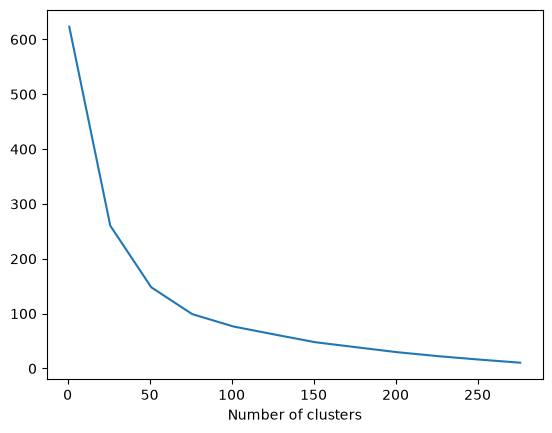

In [382]:
# Cluster inertia across candidate cluster counts.
inertia = []
clusters = 300
step = 25
max_iter = 50
n_init = 5
random_state = 42
for k in range(1, clusters, step):
    kmeans = KMeans(
        n_clusters=k,
        max_iter=max_iter,
        n_init=n_init,
        random_state=random_state,
    ).fit(X_lsa)
    # inertia is the sum of squared distances to the closest cluster center
    inertia.append(kmeans.inertia_)
plt.plot(range(1, clusters, step), inertia)
plt.xlabel('Number of clusters')

There appears to be an elbow about 50, so we'll use 50 clusters.

In [383]:
n_clusters = 50
kmeans = KMeans(
    n_clusters=n_clusters,
    max_iter=max_iter,
    n_init=n_init,
    random_state=random_state,
).fit(X_lsa)


In [384]:
# Map cluster labels back by article ID, preserving the feature-matrix order.
article_cluster_map = dict(zip(df_unique_articles['article_id'], kmeans.labels_))
df['title_cluster'] = df['article_id'].map(article_cluster_map)


In [385]:
# Article counts per cluster.
np.array(np.unique(kmeans.labels_, return_counts=True)).T

array([[ 0, 11],
       [ 1, 37],
       [ 2, 23],
       [ 3, 71],
       [ 4, 20],
       [ 5, 28],
       [ 6, 32],
       [ 7, 19],
       [ 8, 41],
       [ 9, 13],
       [10, 29],
       [11,  6],
       [12, 20],
       [13, 12],
       [14,  7],
       [15, 14],
       [16, 22],
       [17,  4],
       [18,  7],
       [19, 10],
       [20, 10],
       [21,  9],
       [22,  7],
       [23,  9],
       [24,  7],
       [25,  8],
       [26,  9],
       [27, 11],
       [28,  7],
       [29,  5],
       [30, 16],
       [31, 12],
       [32, 12],
       [33,  9],
       [34, 13],
       [35, 10],
       [36, 18],
       [37, 15],
       [38,  8],
       [39,  7],
       [40,  6],
       [41, 18],
       [42,  8],
       [43,  7],
       [44,  5],
       [45,  9],
       [46,  8],
       [47,  7],
       [48,  8],
       [49, 10]])

In [386]:
def get_similar_articles(article_id, df=df):
    """
    INPUT:
    article_id - (int) an article id 
    df - (pandas dataframe) df as defined at the top of the notebook 
    
    OUTPUT:
    article_ids - (list) a list of article ids that are in the same title cluster
    
    Description:
    Returns a list of the article ids that are in the same title cluster
    """
    matches = df.loc[df['article_id'] == article_id, 'title_cluster']
    if matches.empty:
        raise KeyError(f"Unknown article_id: {article_id}")
    title_cluster = matches.iloc[0]
    articles_in_cluster = df.loc[
        (df['title_cluster'] == title_cluster) & (df['article_id'] != article_id),
        'article_id',
    ].drop_duplicates().tolist()
    
    return articles_in_cluster

In [387]:
def make_content_recs(article_id, n, df=df):
    """
    INPUT:
    article_id - (int) an article id
    n - (int) the number of recommendations you want similar to the article id
    df - (pandas dataframe) df as defined at the top of the notebook
    
    OUTPUT:
    n_ranked_similar_articles - (list) a list of article ids that are in the same title cluster ranked
                                by popularity
    n_ranked_article_names - (list) a list of article names associated with the list of article ids
    
    Description:
    Returns a list of the n most ranked similar articles to a given article_id based on the title
    cluster in df. Rank similar articles using the function get_ranked_article_unique_counts.
    """
    if n <= 0:
        return [], []
    similar_articles = get_similar_articles(article_id, df=df)
    # Build counts from the supplied frame so custom datasets are supported.
    ranked_articles = get_ranked_article_unique_counts(
        similar_articles, user_item=create_user_item_matrix(df)
    )
    n_ranked_similar_articles = [pair[0] for pair in ranked_articles[:n]]
    n_ranked_article_names = get_article_names(n_ranked_similar_articles, df=df)
    
    return n_ranked_similar_articles, n_ranked_article_names
        

In [388]:
# Content recommendations for article 25.
rec_article_ids, rec_article_titles = make_content_recs(25, 10)
print(rec_article_ids)
print(rec_article_titles)

[1025, 101, 975, 766, 508, 547, 132, 878, 92, 693]
['data tidying in data science experience', 'how to choose a project to practice data science', 'the data science process', 'making data science a team sport', 'data science in the cloud', 'trust in data science', 'collecting data science cheat sheets', '10 data science podcasts you need to be listening to right now', '9 mistakes to avoid when starting your career in data science', 'better together: spss and data science experience']


In [389]:
assert len({1025, 593, 349, 821, 464, 29, 1042, 693, 524, 352}.intersection(set(rec_article_ids))) > 0, "Oops! Your the make_content_recs function doesn't work quite how we expect."

### Content recommender: interpretation and improvements


My content-based recommender uses article titles to find related articles. It converts each title into numerical features using TF-IDF, reduces those features with truncated SVD, and normalizes them before grouping articles into 50 clusters using k-means. For a given article, it finds other articles in the same cluster, excludes the original article, and recommends those read by the most unique users.

One improvement would be to rank articles by cosine similarity to the selected article rather than relying only on cluster membership and popularity. This could identify closer matches, including articles in other clusters. I could also tune the number of clusters and SVD components and evaluate recommendation quality using held-out interactions.

Article summaries, full article text, topic tags, and keywords would provide more context than titles alone and could help distinguish articles with similar titles but different content.

<a id="Matrix-Fact"></a>
## Matrix Factorization

Truncated SVD learns latent features from the binary user–article interaction matrix.


In [390]:
# quick look at the matrix
user_item.head()

article_id,0,2,4,8,9,12,14,15,16,18,...,1434,1435,1436,1437,1439,1440,1441,1442,1443,1444
user_id,,,,,,,,,,,,,,,,,,,,,
1,0,0,0,0,0,0,0,0,0,0,...,0,0,1,0,1,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,1,0,0,0,0,...,0,0,1,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
5,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


### SVD decomposition


In [391]:
from sklearn.decomposition import TruncatedSVD
from sklearn.metrics import precision_score, recall_score, accuracy_score
# Using the full number of components which equals the number of columns
svd = TruncatedSVD(n_components=len(user_item.columns), n_iter=5, random_state=42)

u = svd.fit_transform(user_item)
v = svd.components_
s = svd.singular_values_ 
print('u', u.shape)
print('s', s.shape)
print('vt', v.shape)

u (5149, 714)
s (714,)
vt (714, 714)


### Reconstruction metrics across latent dimensions


Text(0.5, 1.0, 'Metrics vs. Number of Latent Features')

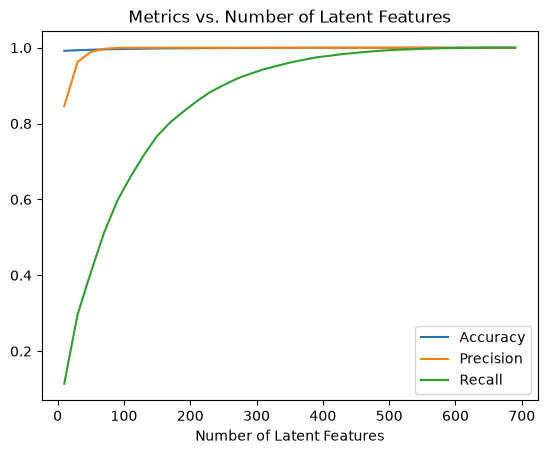

In [392]:
num_latent_feats = np.arange(10, 700+10, 20)
metric_scores = []

for k in num_latent_feats:
    # restructure with k latent features
    u_new, vt_new = u[:, :k], v[:k, :]
    
    # take dot product
    user_item_est = abs(np.around(np.dot(u_new, vt_new))).astype(int)
    # make sure the values are between 0 and 1
    user_item_est = np.clip(user_item_est, 0, 1)
    
    # total errors and keep track of them
    acc = accuracy_score(user_item.values.flatten(), user_item_est.flatten())
    precision = precision_score(user_item.values.flatten(), user_item_est.flatten())
    recall = recall_score(user_item.values.flatten(), user_item_est.flatten())
    metric_scores.append([acc, precision, recall])
    
    
plt.plot(num_latent_feats, metric_scores, label=['Accuracy', 'Precision', 'Recall'])
plt.legend()
plt.xlabel('Number of Latent Features')
plt.title('Metrics vs. Number of Latent Features')

### Selecting the number of latent features


I would use **200 latent features as a starting point**, balancing the ability to capture user–article relationships with computational cost. Adding more features may improve reconstruction of the interaction matrix, but that does not necessarily mean the recommendations become more useful.

I would validate this choice by comparing different feature counts on held-out interactions using precision at 10 and recall at 10. This would help identify which setting best recommends articles users actually interact with.

### Similar articles using 200 latent features


In [393]:
def get_svd_similar_article_ids(article_id, vt, user_item=user_item, include_similarity=False):
    """
    INPUT:
    article_id - (int) an article id
    vt - (numpy array) vt matrix from SVD
    user_item - (pandas dataframe) matrix of users by articles: 
                1's when a user has interacted with an article, 0 otherwise
    include_similarity - (bool) whether to include the similarity in the output
    
    OUTPUT:
    article_ids - (list) article ids ordered by descending latent-feature cosine similarity
    
    Description:
    Returns a list of the article ids similar using SVD factorization
    """
    article_idx = user_item.columns.get_loc(article_id)
    article_features = np.asarray(vt).T
    if article_features.shape[0] != len(user_item.columns):
        raise ValueError("vt must have one column per article in user_item")
    # Compute only the requested article's similarities to avoid a square matrix.
    cos_sim = cosine_similarity(article_features[[article_idx]], article_features)[0]
    ranked_indices = np.argsort(-cos_sim, kind='stable')
    ranked_indices = ranked_indices[ranked_indices != article_idx]
    most_similar_items = user_item.columns[ranked_indices].tolist()

    if include_similarity:
        return [[item, float(cos_sim[idx])] for item, idx in zip(most_similar_items, ranked_indices)]
    return most_similar_items

In [394]:
# Create a vt_new matrix with 200 latent features
k = 200
vt_new = v[:k, :]

In [395]:
# Reference article.
print("Current article:", get_article_names([4], df=df)[0])

Current article: analyze ny restaurant data using spark in dsx


In [396]:
# Ten articles most similar to article 4.
rec_articles = get_svd_similar_article_ids(4, vt_new, user_item=user_item)[:10]
rec_articles

[1199, 1068, 486, 1202, 176, 1120, 244, 793, 58, 132]

In [397]:
# Ten articles most similar to article 4.
get_article_names(rec_articles, df=df)

['country statistics: crude oil - exports',
 'airbnb data for analytics: athens reviews',
 'use spark r to load and analyze data',
 'country statistics: crude oil - proved reserves',
 'top analytics tools in 2016',
 'airbnb data for analytics: paris calendar',
 'notebooks: a power tool for data scientists',
 '10 powerful features on watson data platform, no coding necessary',
 'advancements in the spark community',
 'collecting data science cheat sheets']

In [398]:
assert set(rec_articles) == {1199, 1068, 486, 1202, 176, 1120, 244, 793, 58, 132}, "Oops! Your the get_svd_similar_article_ids function doesn't work quite how we expect."
print("That's right!  Great job!")

That's right!  Great job!


<a id="conclusions"></a>
## Evaluation and Tradeoffs


The SVD recommendations identify articles with similar latent interaction patterns, so they may uncover relationships that are not obvious from article titles. However, similarity alone does not establish that users will find these recommendations useful.

To evaluate improvement, I would hold out a subset of each user’s interactions for evaluation and train only on the remaining interactions. I would also measure recommendation diversity and catalog coverage. An online A/B test could then compare engagement, such as clicks, reading completion, and repeat visits.

Each method has tradeoffs. Popularity-based recommendations are simple and work without user history, but provide little personalization. User-user collaborative filtering uses shared interests but struggles when interaction histories are sparse. Content-based recommendations can suggest new articles without interaction data, although title-only features provide limited context and may produce repetitive suggestions. SVD captures broader interaction patterns efficiently, but its factors are harder to interpret and it cannot directly represent unseen users or articles.

For users with **no history**, I would recommend popular articles, optionally filtered by interests selected during onboarding. For users with **a little history**, I would combine content-based suggestions from articles they have read with popular articles. For users with **substantial history**, I would emphasize collaborative filtering and SVD while retaining content-based suggestions for variety and newly published articles. In every case, I would exclude articles the user has already read.

## HTML Export


In [ ]:
import sys
from pathlib import Path
from subprocess import run

# Support launching the notebook from the project root or starter directory.
notebook_path = Path('Recommendations_with_IBM.ipynb')
if not notebook_path.exists():
    notebook_path = Path('starter') / notebook_path

run(
    [sys.executable, '-m', 'nbconvert', '--to', 'html', str(notebook_path)],
    check=True,
)
